# Data Exploration

In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from ta.momentum import RSIIndicator

### 


In [105]:
# Reading the data 
df = pd.read_csv("Data/price_data.csv", header = 3)
df["Date"] = pd.to_datetime(df['Date'])
df.set_index("Date", inplace=True)
df.head()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_58904/3791631968.py:2: DtypeWarning: Columns (5,64,138,248,268,280,322,355,367,396,447,450,472,509) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Data/price_data.csv", header = 3)


,Line#,LYB UN,AXP UN,VZ UN,TPL UN,AVGO UW,BA UN,SOLV UN,CAT UN,JPM UN,...,ZTS UN,ARES UN,COIN UW,EQIX UW,DLR UN,MOH UN,LVS UN,Unnamed: 546,Unnamed: 547,Unnamed: 548
Date,,,,,,,,,,,,,,,,,,,,,
2010-07-30,6,NaN,36.08,13.66,7.62,1.56,53.77,NaN,47.87,27.04,...,NaN,NaN,NaN,70.34,34.63,19.87,17.26,NaN,NaN,NaN
2010-08-02,9,NaN,36.36,13.90,7.91,1.57,54.99,NaN,48.76,27.95,...,NaN,NaN,NaN,70.71,35.02,20.33,17.96,NaN,NaN,NaN
2010-08-03,10,NaN,36.05,13.89,7.93,1.55,54.87,NaN,48.30,27.57,...,NaN,NaN,NaN,70.74,34.43,20.69,18.07,NaN,NaN,NaN
2010-08-04,11,NaN,35.65,13.82,8.06,1.60,54.98,NaN,48.81,27.72,...,NaN,NaN,NaN,70.88,34.06,21.14,18.56,NaN,NaN,NaN
2010-08-05,12,NaN,34.93,13.89,8.06,1.63,54.55,NaN,49.39,27.70,...,NaN,NaN,NaN,70.71,33.23,18.87,18.35,NaN,NaN,NaN


In [106]:
df["VZ UN"]


Date
2010-07-30    13.66
2010-08-02    13.90
2010-08-03    13.89
2010-08-04    13.82
2010-08-05    13.89
              ...  
2025-07-23    42.84
2025-07-24    43.08
2025-07-25    43.08
2025-07-28    42.36
2025-07-29    42.71
Name: VZ UN, Length: 3773, dtype: float64

<Axes: xlabel='Date'>

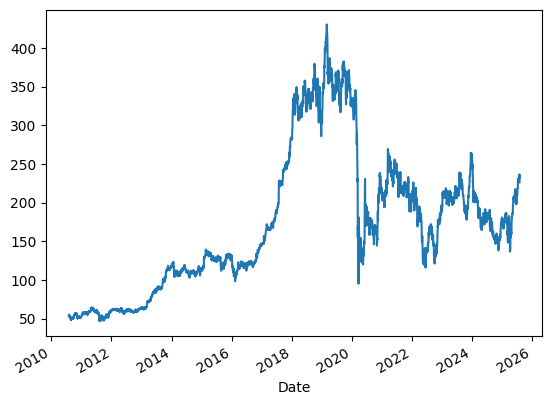

In [162]:
vz_us = df["BA UN"]
vz_us.plot()

In [108]:
print(vz_us)

Date
2025-01-02    171.87
2025-01-03    169.90
2025-01-06    170.78
2025-01-07    172.51
2025-01-08    171.76
               ...  
2025-07-23    233.88
2025-07-24    231.27
2025-07-25    233.06
2025-07-28    236.41
2025-07-29    226.08
Name: BA UN, Length: 142, dtype: float64


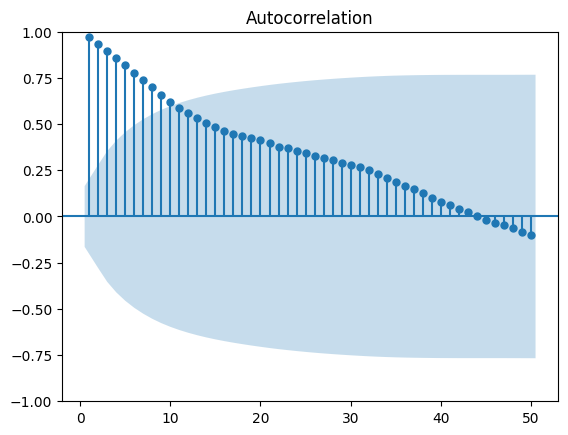

In [109]:
plot_acf(vz_us.dropna(), lags= 50, zero=False)
plt.show()

Date
2010-07-30    34.3300
2010-08-06    34.9940
2010-08-13    34.6460
2010-08-20    34.0640
2010-08-27    32.7800
               ...   
2025-07-04    91.9275
2025-07-11    91.0360
2025-07-18    91.3900
2025-07-25    91.6540
2025-08-01    90.7600
Freq: W-FRI, Name: L UN, Length: 784, dtype: float64


<Figure size 800x400 with 0 Axes>

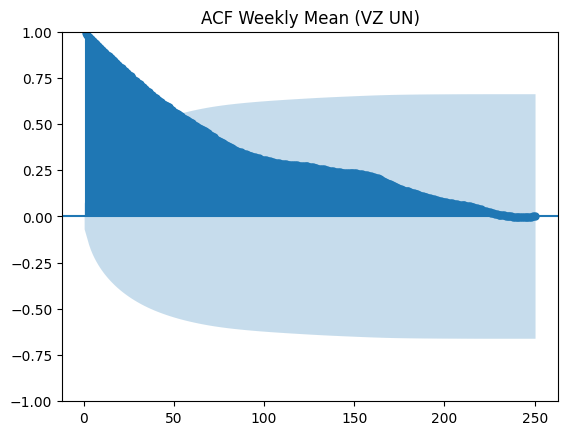

In [110]:
# ...existing code...
weekly_series = df["L UN"].resample("W-FRI").mean()   # weekly mean ending Friday
weekly_series = weekly_series.dropna()
print(weekly_series)

from statsmodels.graphics.tsaplots import plot_acf
plt.figure(figsize=(8,4))
plot_acf(weekly_series, lags=250, zero=False)
plt.title("ACF Weekly Mean (VZ UN)")
plt.show()
# ...existing code...

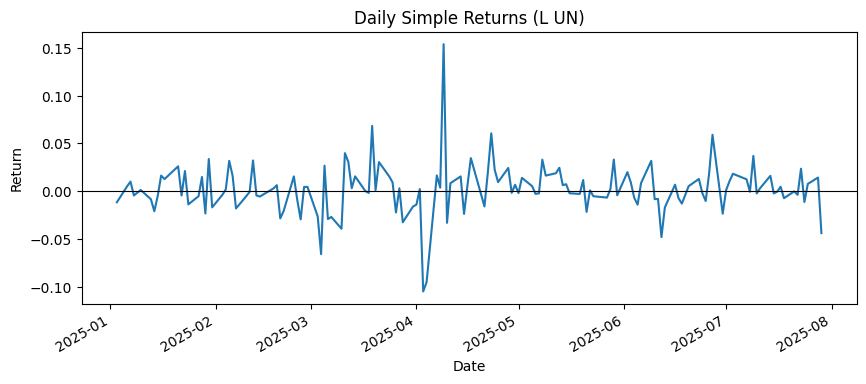

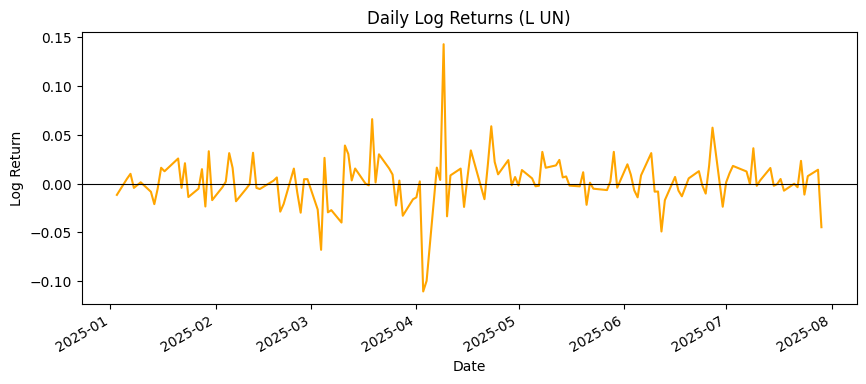

In [111]:
# ...existing code...
# Daily simple return
vz_us_returns = vz_us.pct_change().dropna()

plt.figure(figsize=(10,4))
vz_us_returns.plot(title="Daily Simple Returns (L UN)")
plt.ylabel("Return")
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

# Optional: log returns
vz_us_log_returns = np.log(vz_us / vz_us.shift(1)).dropna()

plt.figure(figsize=(10,4))
vz_us_log_returns.plot(title="Daily Log Returns (L UN)", color='orange')
plt.ylabel("Log Return")
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

In [112]:
percentage_change = vz_us.pct_change()
print(percentage_change)

Date
2025-01-02         NaN
2025-01-03   -0.011462
2025-01-06    0.005180
2025-01-07    0.010130
2025-01-08   -0.004348
                ...   
2025-07-23    0.023634
2025-07-24   -0.011160
2025-07-25    0.007740
2025-07-28    0.014374
2025-07-29   -0.043695
Name: BA UN, Length: 142, dtype: float64


<Axes: xlabel='Date'>

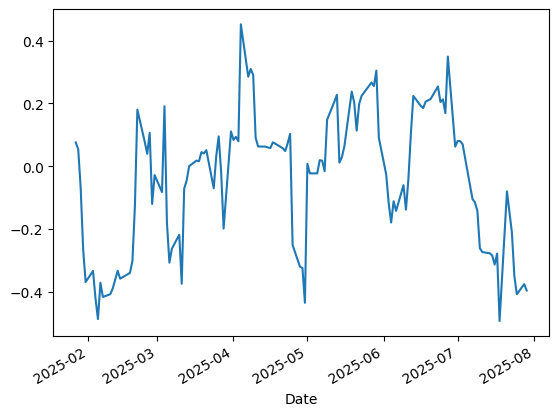

In [113]:
window = 14
correlation_score = percentage_change.rolling(window=window).corr(percentage_change.shift(1))
correlation_score.plot()

In [114]:
print(correlation_score)

Date
2025-01-02         NaN
2025-01-03         NaN
2025-01-06         NaN
2025-01-07         NaN
2025-01-08         NaN
                ...   
2025-07-23   -0.209474
2025-07-24   -0.347526
2025-07-25   -0.405845
2025-07-28   -0.373671
2025-07-29   -0.393859
Name: BA UN, Length: 142, dtype: float64


In [127]:
rsi_inicator = RSIIndicator(close=vz_us, window=14)
vz_us_rsi = rsi_inicator.rsi()
print(vz_us_rsi)

Date
2025-01-02          NaN
2025-01-03          NaN
2025-01-06          NaN
2025-01-07          NaN
2025-01-08          NaN
                ...    
2025-07-23    72.939283
2025-07-24    67.319495
2025-07-25    69.079072
2025-07-28    72.106028
2025-07-29    54.416247
Name: rsi, Length: 142, dtype: float64


In [195]:
def calculate_trend_reversion_score(price_series, ac_window=14, rsi_window=14):
    
    # Calculating auto correlation score
    returns = price_series.pct_change()
    score_ac = returns.rolling(window=ac_window).corr(returns.shift(1))

    # --- 2. RSI Momentum Score (Score_RSI) ---
    rsi = RSIIndicator(close=price_series, window=rsi_window).rsi()
    
    # Define RSI zones
    rsi_oversold = 30
    rsi_overbought = 70
    rsi_strong_down = 40
    rsi_strong_up = 60

    score_rsi = np.select(
        [
            rsi > rsi_overbought,  # Overbought -> Mean Reversion signal
            rsi < rsi_oversold,    # Oversold -> Mean Reversion signal
            rsi.between(rsi_strong_up, rsi_overbought), # Strong uptrend momentum -> Trend signal
            rsi.between(rsi_oversold, rsi_strong_down), # Strong downtrend momentum -> Trend signal
        ],
        [
            -1 * ((rsi - rsi_overbought) / (100 - rsi_overbought)), # Scale from 0 to -1
            -1 * ((rsi_oversold - rsi) / rsi_oversold),             # Scale from 0 to -1
            1, # Strong trend
            1  # Strong trend
        ],
        default=0 # Neutral zone
    )

    # --- 3. Combine for Final Score ---
    weights = {"AC": 0.7, "RSI": 0.3}
    total_score = (weights['AC'] * score_ac + weights['RSI'] * score_rsi)

    return total_score.dropna()

In [ ]:
calculate_trend_reversion_score(vz_us)


Date
2025-01-27    0.053484
2025-01-28    0.338144
2025-01-29   -0.048507
2025-01-30    0.115444
2025-01-31   -0.257065
                ...   
2025-07-23   -0.176025
2025-07-24    0.056732
2025-07-25    0.015908
2025-07-28   -0.282630
2025-07-29   -0.275701
Name: BA UN, Length: 127, dtype: float64

2025-01-06 00:00:00


In [194]:
def backtest_trend_reversion_score(price_series, score_threshold = 0.3, prediction_window = 14, price_threshold = 0.05):
    scores = calculate_trend_reversion_score(price_series, ac_window=prediction_window, rsi_window=prediction_window)

    aligned_data = pd.DataFrame({
        'price': price_series,
        'score': scores
    }).dropna()


    predictions = []
    

    for i in range(len(aligned_data) - prediction_window):
        current_date = aligned_data.index[i]
        current_price = aligned_data.iloc[i]['price']
        current_score = aligned_data.iloc[i]['score']

        future_price = aligned_data.iloc[i + prediction_window]['price']
        price_change_pct = (future_price - current_price) / current_price

        if current_score <= -score_threshold:
            prediction = "mean_reversion"
            actual_outcome = "correct" if abs(price_change_pct) <= price_threshold else "incorrect"
        elif current_score >= score_threshold:
            prediction = "trending"
            actual_outcome = "correct" if abs(price_change_pct) >= price_threshold else "incorrect"
        else:
            continue


        predictions.append({
            'date': current_date,
            'price': current_price,
            'score': current_score,
            'prediction': prediction,
            'future_price': future_price,
            'price_change_pct': price_change_pct,
            'outcome': actual_outcome
        })


    # Convert to DataFrame for analysis
    results_df = pd.DataFrame(predictions)
    
    if len(results_df) == 0:
        return {"error": "No predictions made. Try lowering the score_threshold."}
    
    # Calculate accuracy metrics
    total_predictions = len(results_df)
    correct_predictions = len(results_df[results_df['outcome'] == 'correct'])
    overall_accuracy = correct_predictions / total_predictions * 100

    print("Total predictions made:", total_predictions)
    print("Correct predictions:", correct_predictions)
 

    return overall_accuracy


In [196]:
backtest_trend_reversion_score(vz_us, score_threshold=0.3, prediction_window=120, price_threshold=0.05)

Total predictions made: 182
Correct predictions: 179


/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_58904/334975336.py:4: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = price_series.pct_change()


98.35164835164835

In [199]:
stock_columns = df.columns.tolist()[1:]
stock_len = len(stock_columns)
total_accuracy = 0

for stock_symbol in stock_columns:
    stock_data = df[stock_symbol]
    stock_data = pd.to_numeric(stock_data, errors='coerce').dropna()
    accuracy = backtest_trend_reversion_score(stock_data, score_threshold=0, prediction_window=120, price_threshold=0.05)
    print(accuracy)
    if isinstance(accuracy, dict):
        stock_len -= 1
    else:    
        total_accuracy += accuracy

print("total accuracy:", total_accuracy / stock_len)

Total predictions made: 3478
Correct predictions: 1649
47.41230592294422
Total predictions made: 3531
Correct predictions: 1785
50.552251486830926
Total predictions made: 3531
Correct predictions: 1830
51.82667799490229
Total predictions made: 3338
Correct predictions: 1556
46.61473936488916
Total predictions made: 3531
Correct predictions: 1621
45.9076748796375
Total predictions made: 3531
Correct predictions: 1771
50.155763239875384
Total predictions made: 95
Correct predictions: 44
46.31578947368421
Total predictions made: 3531
Correct predictions: 1915
54.233928065703765
Total predictions made: 3531
Correct predictions: 1725
48.85301614273577
Total predictions made: 3531
Correct predictions: 1998
56.58453695836874
Total predictions made: 3531
Correct predictions: 1264
35.79722458227131
Total predictions made: 2936
Correct predictions: 1435
48.87602179836512
Total predictions made: 3531
Correct predictions: 1359
38.48768054375531
Total predictions made: 3435
Correct predictions: 179

KeyboardInterrupt: 

In [180]:
print(df["AAPL UW"])

Date
2010-07-30      7.73
2010-08-02      7.87
2010-08-03      7.87
2010-08-04      7.90
2010-08-05      7.87
               ...  
2025-07-23    214.15
2025-07-24    213.76
2025-07-25    213.88
2025-07-28    214.05
2025-07-29    211.27
Name: AAPL UW, Length: 3773, dtype: float64


<Axes: xlabel='Date'>

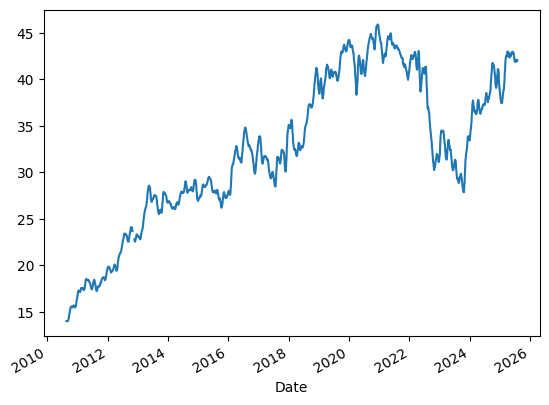

In [ ]:
ma_window = 14
moving_average = vz_us.rolling(window=ma_window).mean()
moving_average.plot()
    

Date
2010-07-30         NaN
2010-08-02         NaN
2010-08-03         NaN
2010-08-04         NaN
2010-08-05         NaN
                ...   
2025-07-23    0.903571
2025-07-24    1.127857
2025-07-25    1.059286
2025-07-28    0.340714
2025-07-29    0.635000
Name: VZ UN, Length: 3773, dtype: float64


<Axes: xlabel='Date'>

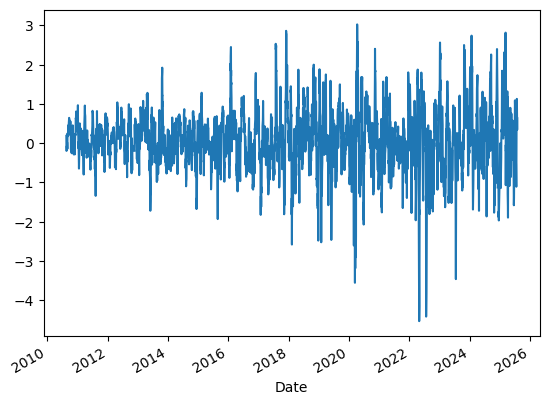

In [ ]:
# calculate how the data deviate from the mean
deviation = vz_us - moving_average
print(deviation)
deviation.plot()



In [ ]:
the_mean = 0
above_mean = deviation > 0


In [ ]:
crossing = (above_mean != above_mean.shift(1)) & (above_mean.shift(1).notna())
crossing_dates = vz_us[crossing].index
print(crossing_dates)

DatetimeIndex(['2010-08-18', '2010-08-19', '2010-08-27', '2010-08-30',
               '2010-09-01', '2010-10-12', '2010-10-27', '2010-10-28',
               '2010-10-29', '2010-11-01',
               ...
               '2025-05-22', '2025-05-27', '2025-05-28', '2025-05-30',
               '2025-06-04', '2025-06-06', '2025-06-12', '2025-06-30',
               '2025-07-09', '2025-07-21'],
              dtype='datetime64[ns]', name='Date', length=531, freq=None)


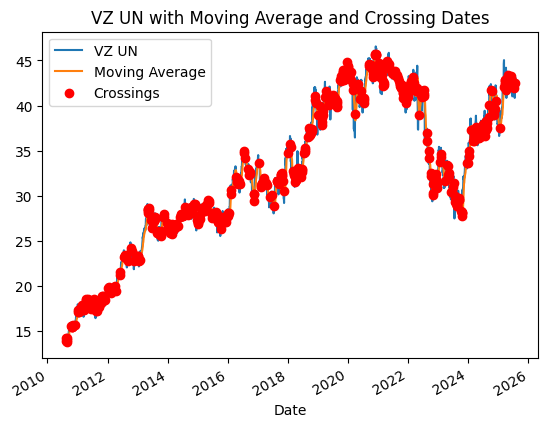

In [ ]:

vz_us.plot(label="VZ UN")
moving_average.plot(label="Moving Average")

# Mark crossing dates
plt.scatter(crossing_dates, vz_us[crossing_dates], color='red', label='Crossings', zorder=3)

plt.legend()
plt.title("VZ UN with Moving Average and Crossing Dates")
plt.show()

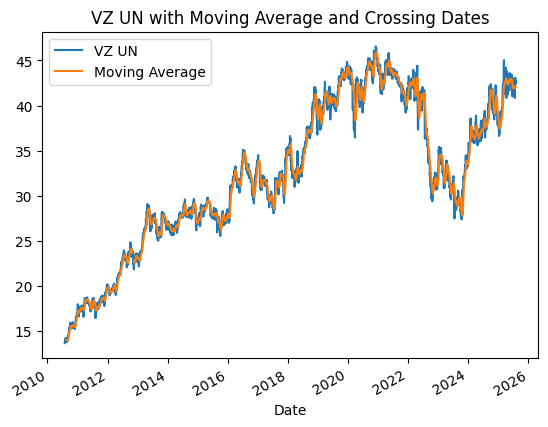

In [ ]:

vz_us.plot(label="VZ UN")
moving_average.plot(label="Moving Average")

# Mark crossing dates

plt.legend()
plt.title("VZ UN with Moving Average and Crossing Dates")
plt.show()

In [ ]:
time_between_crossings = pd.Series(crossing_dates).diff().dt.days.dropna()
print(time_between_crossings.unique())


[ 1.  8.  3.  2. 41. 15.  9. 21. 40. 11. 20.  5.  6.  4.  7. 25. 24. 13.
 10. 19. 36. 14. 16. 22. 45. 43. 37. 33. 26. 98. 30. 12. 32. 34. 31. 55.
 54. 38. 18. 27. 44. 28. 23. 35. 62. 17. 29. 53.]


In [ ]:
#average crossing time - extension will be a more robust model with more explanatory variables and deternmining where you are in the mean reverse cycle
average_crossing_time = time_between_crossings.mean()
print(average_crossing_time)

median_crossing_time = time_between_crossings.median()
print(median_crossing_time)

10.284905660377358
6.0


<Axes: xlabel='Date'>

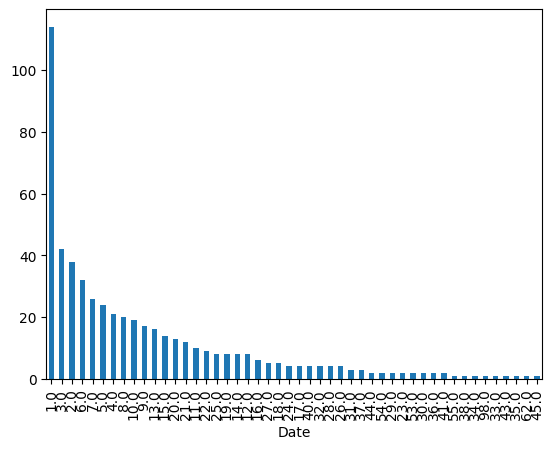

In [ ]:
time_between_crossings_count = time_between_crossings.value_counts()
time_between_crossings_count.plot.bar()